<a href="https://colab.research.google.com/github/nabilah-afrin/Computer-vision-projects/blob/main/A%20Comprehensive%20Analysis%20of%20Training%20Dynamic%20Properties%20in%20Deep%20Neural%20Networks%20with%20CutMix%20Augmentation/Results/Loss_Landscape_ConvMixer_Cifar_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
# import ResNet_BN
import pickle
import matplotlib.pyplot as plt


sys.path.append('/content/sample_data')

In [ ]:
# import ResNet_BN
# model = ResNet_BN.ResNet18(num_classes=10)
# # model.build(input_shape=(None, 32, 32, 3))
# # model.summary()

In [ ]:
lr = [5e-3, 1e-3, 5e-4, 1e-4]

In [ ]:
h_cutmix = [
    '/content/ConvMixer_10_Normal_5e-03.pkl',
    '/content/ConvMixer_10_Normal_1e-03.pkl',
    '/content/ConvMixer_10_Normal_5e-04.pkl',
    '/content/ConvMixer_10_Normal_1e-04.pkl'
]

histories_cutmix = {}
for i in range(len(lr)):
    with open(h_cutmix[i], 'rb') as f:
        history = pickle.load(f)
        histories_cutmix[lr[i]] = history

In [ ]:
h = [
    '/content/ResNet_10_Normal_5e-03.pkl',
    '/content/ResNet_10_Normal_1e-03.pkl',
    '/content/ResNet_10_Normal_5e-04.pkl',
    '/content/ResNet_10_Normal_1e-04.pkl'
]

histories= {}
for i in range(len(lr)):
    with open(h[i], 'rb') as f:
        history = pickle.load(f)
        histories[lr[i]] = history

In [ ]:
# def plot_comparison_histories(histories_cutmix, histories):
#     num_histories = len(histories_cutmix)

#     fig, axes = plt.subplots(2, num_histories, figsize=(5 * num_histories, 10))

#     for i, lr in enumerate(histories_cutmix.keys()):
#         history_cutmix = histories_cutmix[lr]
#         history = histories[lr]

#         # Accuracy plots
#         axes[0, i].plot(history_cutmix["accuracy"], label="Train Acc Normal + ConvMixer", color='green')
#         axes[0, i].plot(history_cutmix["val_accuracy"], label="Val Acc Normal + ConvMixer", color='green', linestyle='--')
#         axes[0, i].plot(history["accuracy"], label="Train Acc Normal + ResNet", color='red')
#         axes[0, i].plot(history["val_accuracy"], label="Val Acc Normal + ResNet", color='red', linestyle='--')
#         axes[0, i].set_title(f"Accuracy (LR: {lr})")
#         axes[0, i].set_xlabel("Epochs")
#         axes[0, i].set_ylabel("Accuracy")
#         axes[0, i].legend()
#         axes[0, i].grid()

#         # Loss plots
#         axes[1, i].plot(history_cutmix["loss"], label="Train Loss Normal + ConvMixer", color='green')
#         axes[1, i].plot(history_cutmix["val_loss"], label="Val Loss Normal + ConvMixer", color='green', linestyle='--')
#         axes[1, i].plot(history["loss"], label="Train Loss Normal+ ResNet", color='red')
#         axes[1, i].plot(history["val_loss"], label="Val Loss Normal+ ResNet", color='red', linestyle='--')
#         axes[1, i].set_title(f"Loss (LR: {lr})")
#         axes[1, i].set_xlabel("Epochs")
#         axes[1, i].set_ylabel("Loss")
#         axes[1, i].legend()
#         axes[1, i].grid()

#     # Set a title for the entire subplot
#     fig.suptitle("Histories with Standard Augmentation: Cifar-100, ConvMixer", fontsize=16)

#     plt.tight_layout()
#     plt.show()

# plot_comparison_histories(histories_cutmix, histories)


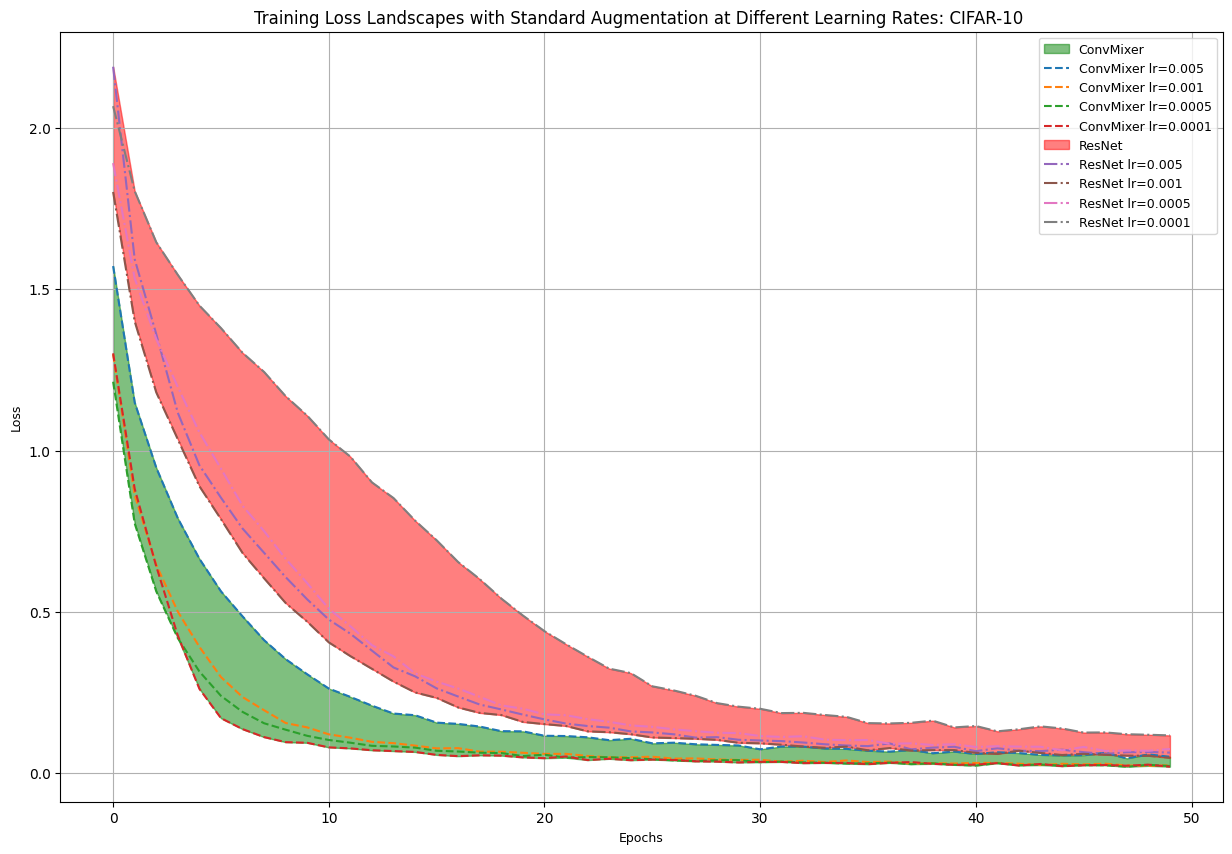

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_loss_landscapes(histories_bn, histories_no_bn):

    losses_bn = {lr: np.array(hist["loss"]) for lr, hist in histories_cutmix.items()}
    losses_no_bn = {lr: np.array(hist["loss"]) for lr, hist in histories.items()}


    min_length_bn = min(len(loss) for loss in losses_bn.values())
    min_length_no_bn = min(len(loss) for loss in losses_no_bn.values())
    min_length = min(min_length_bn, min_length_no_bn)


    min_curve_bn, max_curve_bn, mean_curve_bn = [], [], []
    min_curve_no_bn, max_curve_no_bn, mean_curve_no_bn = [], [], []


    for i in range(min_length):
        loss_values_at_epoch_bn = [loss[i] for loss in losses_bn.values()]
        min_curve_bn.append(np.min(loss_values_at_epoch_bn))
        max_curve_bn.append(np.max(loss_values_at_epoch_bn))
        mean_curve_bn.append(np.mean(loss_values_at_epoch_bn))


    for i in range(min_length):
        loss_values_at_epoch_no_bn = [loss[i] for loss in losses_no_bn.values()]
        min_curve_no_bn.append(np.min(loss_values_at_epoch_no_bn))
        max_curve_no_bn.append(np.max(loss_values_at_epoch_no_bn))
        # mean_curve_no_bn.append(np.mean(loss_values_at_epoch_no_bn))

    plt.figure(figsize=(15, 10))


    plt.fill_between(range(min_length), min_curve_bn, max_curve_bn, color='green', alpha=0.5, label='ConvMixer')

    # plt.plot(mean_curve_bn, color='green', linestyle='-', label='Mean loss')
    for lr, losses in losses_bn.items():
        plt.plot(losses[:min_length], label=f'ConvMixer lr={lr}', linestyle='--')



    plt.fill_between(range(min_length), min_curve_no_bn, max_curve_no_bn, color='red', alpha=0.5, label='ResNet')
    # plt.plot(mean_curve_no_bn, color='red', linestyle='-', label='Mean loss')
    for lr, losses in losses_no_bn.items():
        plt.plot(losses[:min_length], label=f'ResNet lr={lr}', linestyle='-.')

    plt.xlabel('Epochs', fontsize=9)
    plt.ylabel('Loss', fontsize=9)
    plt.title('Training Loss Landscapes with Standard Augmentation at Different Learning Rates: CIFAR-10 ')
    plt.legend(loc='best', fontsize=9)
    # plt.show()
    # plt.legend()
    plt.grid(True)
    plt.show()

plot_loss_landscapes(histories_cutmix, histories)


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# #############################       with Batch norm #############################################

# losses_bn = {lr: np.array(hist["loss"]) for lr, hist in histories_bn.items()}


# min_length_bn = min(len(loss) for loss in losses_bn.values())


# min_curve_bn = []
# max_curve_bn = []
# mean_curve_bn = []


# for i in range(min_length_bn):
#     loss_values_at_epoch_bn = [loss[i] for loss in losses_bn.values()]
#     min_curve_bn.append(np.min(loss_values_at_epoch_bn))
#     max_curve_bn.append(np.max(loss_values_at_epoch_bn))
#     mean_curve_bn.append(np.mean(loss_values_at_epoch_bn))

# plt.figure(figsize=(15, 10))

# for lr, loss in losses_bn.items():
#     plt.plot(loss[:min_length_bn], label=f'LR {lr}', linestyle='--')


# plt.fill_between(range(min_length_bn), min_curve_bn, max_curve_bn, color='green', alpha=0.5, label='Range between min and max loss')


# plt.plot(mean_curve_bn, color='black', label='Mean loss')

# plt.xlabel('Epochs')
# plt.ylabel('Loss')
# plt.title('Training Loss over Epochs with BatchNorm at Different Learning Rates for ResNet')
# plt.legend()
# plt.grid(True)
# plt.show()

# ############################################ without batch norm ######################################################


# losses_no_bn = {lr: np.array(hist["loss"]) for lr, hist in histories_no_bn.items()}


# min_length_no_bn = min(len(loss) for loss in losses_no_bn.values())


# min_curve_no_bn = []
# max_curve_no_bn = []
# mean_curve_no_bn = []


# for i in range(min_length_no_bn):
#     loss_values_at_epoch_no_bn = [loss[i] for loss in losses_no_bn.values()]
#     min_curve_no_bn.append(np.min(loss_values_at_epoch_no_bn))
#     max_curve_no_bn.append(np.max(loss_values_at_epoch_no_bn))
#     mean_curve_no_bn.append(np.mean(loss_values_at_epoch_no_bn))

# plt.figure(figsize=(15, 10))


# for lr, loss in losses_no_bn.items():
#     plt.plot(loss[:min_length_no_bn], label=f'LR {lr}', linestyle='--')


# plt.fill_between(range(min_length_no_bn), min_curve_no_bn, max_curve_no_bn, color='red', alpha=0.5, label='Range between min and max loss')


# plt.plot(mean_curve_no_bn, color='black', label='Mean loss')


# plt.xlabel('Epochs')
# plt.ylabel('Loss')
# plt.title('Training Loss over Epochs without BatchNorm at Different Learning Rates for ResNet')
# plt.legend()
# plt.grid(True)


# plt.show()


In [ ]:
h_cutmix = [
    '/content/ConvMixer_10_CutMix_5e-03.pkl',
    '/content/ConvMixer_10_CutMix_1e-03.pkl',
    '/content/ConvMixer_10_CutMix_5e-04.pkl',
    '/content/ConvMixer_10_CutMix_1e-04.pkl'
]

histories_cutmix = {}
for i in range(len(lr)):
    with open(h_cutmix[i], 'rb') as f:
        history = pickle.load(f)
        histories_cutmix[lr[i]] = history

In [ ]:
h = [
    '/content/ResNet_10_Cutmix_5e-03.pkl',
    '/content/ResNet_10_Cutmix_1e-03.pkl',
    '/content/ResNet_10_Cutmix_5e-04.pkl',
    '/content/ResNet_10_Cutmix_1e-04.pkl'
]

histories= {}
for i in range(len(lr)):
    with open(h[i], 'rb') as f:
        history = pickle.load(f)
        histories[lr[i]] = history

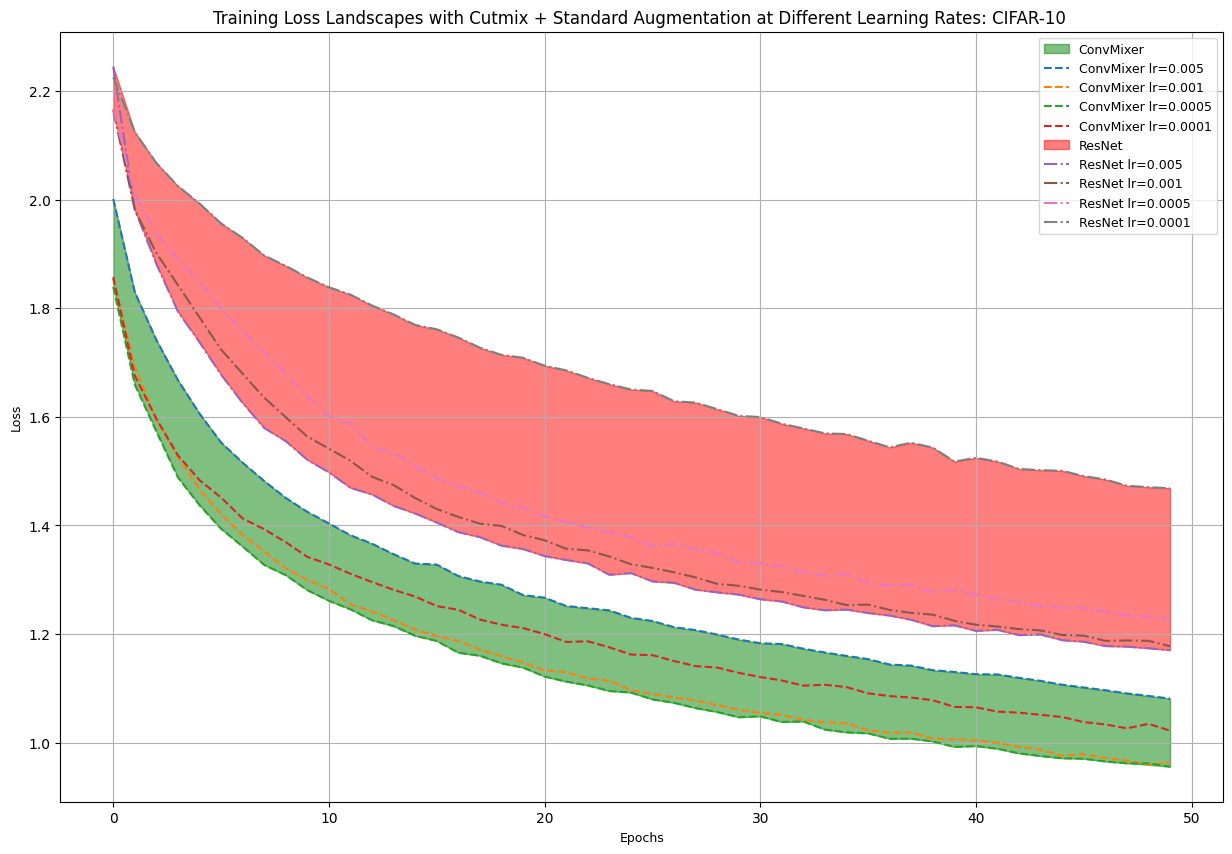

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_loss_landscapes(histories_bn, histories_no_bn):

    losses_bn = {lr: np.array(hist["loss"]) for lr, hist in histories_cutmix.items()}
    losses_no_bn = {lr: np.array(hist["loss"]) for lr, hist in histories.items()}


    min_length_bn = min(len(loss) for loss in losses_bn.values())
    min_length_no_bn = min(len(loss) for loss in losses_no_bn.values())
    min_length = min(min_length_bn, min_length_no_bn)


    min_curve_bn, max_curve_bn, mean_curve_bn = [], [], []
    min_curve_no_bn, max_curve_no_bn, mean_curve_no_bn = [], [], []


    for i in range(min_length):
        loss_values_at_epoch_bn = [loss[i] for loss in losses_bn.values()]
        min_curve_bn.append(np.min(loss_values_at_epoch_bn))
        max_curve_bn.append(np.max(loss_values_at_epoch_bn))
        # mean_curve_bn.append(np.mean(loss_values_at_epoch_bn))


    for i in range(min_length):
        loss_values_at_epoch_no_bn = [loss[i] for loss in losses_no_bn.values()]
        min_curve_no_bn.append(np.min(loss_values_at_epoch_no_bn))
        max_curve_no_bn.append(np.max(loss_values_at_epoch_no_bn))
        # mean_curve_no_bn.append(np.mean(loss_values_at_epoch_no_bn))

    plt.figure(figsize=(15, 10))


    plt.fill_between(range(min_length), min_curve_bn, max_curve_bn, color='green', alpha=0.5, label='ConvMixer')

    # plt.plot(mean_curve_bn, color='green', linestyle='-', label='Mean loss')
    for lr, losses in losses_bn.items():
        plt.plot(losses[:min_length], label=f'ConvMixer lr={lr}', linestyle='--')

    plt.fill_between(range(min_length), min_curve_no_bn, max_curve_no_bn, color='red', alpha=0.5, label='ResNet')
    # plt.plot(mean_curve_no_bn, color='red', linestyle='-', label='Mean loss')
    for lr, losses in losses_no_bn.items():
        plt.plot(losses[:min_length], label=f'ResNet lr={lr}', linestyle='-.')

    plt.xlabel('Epochs', fontsize=9)
    plt.ylabel('Loss', fontsize=9)
    plt.title('Training Loss Landscapes with Cutmix + Standard Augmentation at Different Learning Rates: CIFAR-10 ')
    plt.legend(loc='best', fontsize=9)
    # plt.show()
    # plt.legend()
    plt.grid(True)
    plt.show()

plot_loss_landscapes(histories_cutmix, histories)
